# 05 Horizon strategies

We need forecasts for 1 to 14 weeks ahead. Three ways to get them from LightGBM:

- **Recursive**: one model that predicts one week ahead; its forecasts are fed back in as lags to reach later weeks.
- **Direct**: one model per horizon. Model *h* predicts the week *h* steps ahead directly from features known at the cutoff.
- **Horizon-safe lags**: one model whose lags are all at least 14 weeks old, so every feature is observed for every target week and nothing needs to be fed back.

Same data, same scaler, same LightGBM parameters, same evaluation rows. Only the strategy changes. Runs in about a minute and a half.


In [1]:
import os
import sys
import warnings

if "google.colab" in sys.modules:
    !git clone -q https://github.com/tackes/time-series-forecasting-bootcamp
    %cd time-series-forecasting-bootcamp
    %pip install -q statsforecast==2.1.1 mlforecast==1.1.0 utilsforecast==0.2.17 lightgbm==4.7.0 catboost==1.2.10
elif not os.path.exists("shared"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

In [2]:
import time
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from mlforecast import MLForecast
from mlforecast.lag_transforms import RollingMean
from mlforecast.target_transforms import LocalStandardScaler

from shared.prepare_data import load_panel, H, FREQ, ALL_CUTOFFS, DEV_CUTOFFS, TEST_CUTOFF
from shared.features import LAGS, LAG_TRANSFORMS, DATE_FEATURES, LGB_PARAMS
from shared.leaderboard import to_long, save_forecasts, load_forecasts, leaderboard, breakdown

panel = load_panel()
actuals = panel[["unique_id", "ds", "y"]]

## Which lags exist at each horizon

Standing at the cutoff, the lag-*k* value for a target *h* weeks ahead is observed only if *k* is at least *h*. Otherwise it refers to a week that hasn't happened yet.

- Recursive: for lags smaller than *h* the value is the model's own earlier forecast.
- Direct: model *h* is trained with lags measured from the cutoff, so every input is observed by construction.
- Horizon-safe: lags are 14 or more, so they are observed for all *h* up to 14.

In [3]:
lags = [1, 2, 3, 4, 8, 13, 14, 17, 21]
horizons = [1, 2, 4, 8, 14]
pd.DataFrame({f"h={h}": ["observed" if k >= h else "forecast" for k in lags] for h in horizons}, index=[f"lag{k}" for k in lags])

,h=1,h=2,h=4,h=8,h=14
lag1,observed,forecast,forecast,forecast,forecast
lag2,observed,observed,forecast,forecast,forecast
lag3,observed,observed,forecast,forecast,forecast
lag4,observed,observed,observed,forecast,forecast
lag8,observed,observed,observed,observed,forecast
lag13,observed,observed,observed,observed,forecast
lag14,observed,observed,observed,observed,observed
lag17,observed,observed,observed,observed,observed
lag21,observed,observed,observed,observed,observed


## The three setups

The recursive model is the 02 baseline. Direct training uses `max_horizon=H` in `fit`, which builds a training set and a model for each horizon. The horizon-safe model uses lags and rolling means that start at lag 14.

In [4]:
def make_model(name, lags, lag_transforms):
    return MLForecast(
        models={name: lgb.LGBMRegressor(**LGB_PARAMS)},
        freq=FREQ,
        lags=lags,
        lag_transforms=lag_transforms,
        date_features=DATE_FEATURES,
        target_transforms=[LocalStandardScaler()],
        num_threads=1,
    )

mlf_recursive = make_model("lgbm_recursive", LAGS, LAG_TRANSFORMS)
mlf_direct = make_model("lgbm_direct", LAGS, LAG_TRANSFORMS)

safe_lags = [14, 15, 16, 17, 21, 26]
safe_transforms = {14: [RollingMean(window_size=4), RollingMean(window_size=13), RollingMean(window_size=26)]}
mlf_safe = make_model("lgbm_horizon_safe", safe_lags, safe_transforms)

## Training cost at the final cutoff

Seconds to fit and forecast 14 weeks for 2,000 series on one CPU thread.

In [5]:
train = actuals[actuals.ds <= TEST_CUTOFF]
cost = {}

start = time.perf_counter()
mlf_recursive.fit(train)
mlf_recursive.predict(H)
cost["recursive"] = time.perf_counter() - start

start = time.perf_counter()
mlf_direct.fit(train, max_horizon=H)
mlf_direct.predict(H)
cost["direct"] = time.perf_counter() - start

start = time.perf_counter()
mlf_safe.fit(train)
mlf_safe.predict(H)
cost["horizon_safe"] = time.perf_counter() - start

pd.Series(cost, name="seconds").round(1)

recursive       0.6
direct          6.2
horizon_safe    0.5
Name: seconds, dtype: float64

## Every origin

Recursive forecasts are the 02 baseline (`lgbm_baseline`), so they are loaded instead of refit. Direct and horizon-safe are fit at each cutoff.

In [6]:
forecasts = []
for cutoff in ALL_CUTOFFS:
    train = actuals[actuals.ds <= cutoff]

    mlf_direct.fit(train, max_horizon=H)
    forecasts.append(to_long(mlf_direct.predict(H), cutoff, "05_horizon_strategies"))

    mlf_safe.fit(train)
    forecasts.append(to_long(mlf_safe.predict(H), cutoff, "05_horizon_strategies"))

forecasts = pd.concat(forecasts)

In [7]:
recursive = load_forecasts(["02_ml_baseline"]).query("model == 'lgbm_baseline'").assign(model="lgbm_recursive")
reference = load_forecasts(["01_baselines"]).query("model == 'HistoricAverage'")
candidates = pd.concat([reference, recursive, forecasts])

columns = ["model", "wape", "accuracy", "bias", "mean_rmsse", "median_rmsse", "apc", "apc_median"]
leaderboard(candidates, actuals, scope="dev")[columns].round(3)

,model,wape,accuracy,bias,mean_rmsse,median_rmsse,apc,apc_median
0,lgbm_direct,0.398,0.602,-0.033,1.765,0.873,0.150,0.181
1,HistoricAverage,0.426,0.574,-0.061,1.791,0.887,0.019,0.020
2,lgbm_horizon_safe,0.427,0.573,-0.012,1.806,0.907,0.099,0.112
3,lgbm_recursive,0.449,0.551,0.139,1.865,0.921,0.136,0.142


In [8]:
leaderboard(candidates, actuals, scope="test")[columns].round(3)

,model,wape,accuracy,bias,mean_rmsse,median_rmsse,apc,apc_median
0,lgbm_direct,0.380,0.620,-0.033,1.301,0.694,0.145,0.157
1,lgbm_horizon_safe,0.416,0.584,-0.061,1.378,0.757,0.037,0.042
2,lgbm_recursive,0.419,0.581,0.109,1.302,0.733,0.100,0.089
3,HistoricAverage,0.426,0.574,-0.011,1.367,0.739,0.012,0.013


## By horizon

Development origins, same rows for every model. Horizon 1 is the first week after the cutoff.

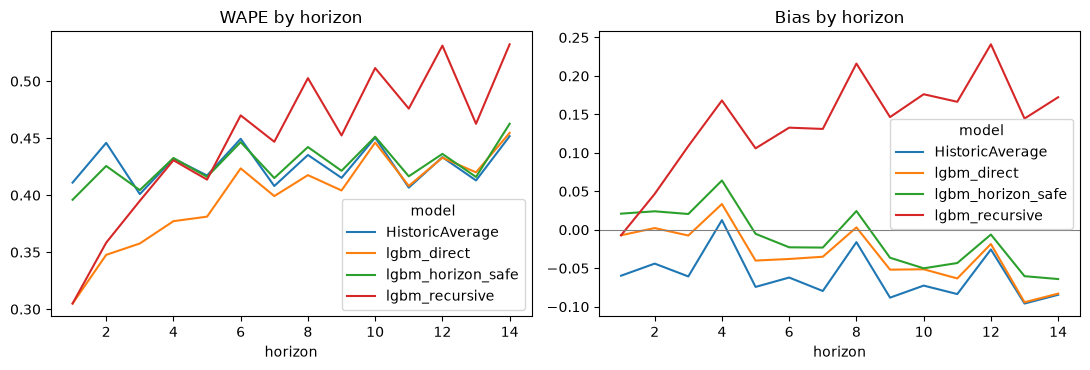

In [9]:
by_horizon = breakdown(candidates, actuals, "horizon", scope="dev")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
by_horizon.pivot(index="horizon", columns="model", values="wape").plot(ax=axes[0], title="WAPE by horizon")
by_horizon.pivot(index="horizon", columns="model", values="bias").plot(ax=axes[1], title="Bias by horizon")
axes[1].axhline(0, color="grey", lw=0.8)
plt.tight_layout()

In [10]:
by_horizon.pivot(index="horizon", columns="model", values="wape").round(3)

model,HistoricAverage,lgbm_direct,lgbm_horizon_safe,lgbm_recursive
horizon,,,,
1,0.411,0.305,0.396,0.305
2,0.446,0.348,0.426,0.358
3,0.401,0.358,0.404,0.395
4,0.432,0.377,0.433,0.431
5,0.417,0.381,0.416,0.414
6,0.449,0.424,0.447,0.470
7,0.408,0.399,0.415,0.447
8,0.435,0.418,0.442,0.503
9,0.415,0.404,0.421,0.452


### Reading the result

Development WAPE: direct 0.398, horizon-safe 0.427, recursive 0.449; bias -0.033, -0.012 and +0.139. The final window keeps the order (0.380, 0.416, 0.419).

At horizon 1, recursive and direct solve the same problem and score the same. The recursive error then grows faster with the horizon, and its bias is positive overall, while the direct model's bias stays small. The horizon-safe model is nearly flat across horizons because it never sees the most recent 13 weeks; it gives up accuracy at short horizons for a single, cheap model and stable forecasts (lowest APC of the three).

Direct needs 14 models per cutoff, which is why it costs several times more to train.

In [11]:
save_forecasts(forecasts, "05_horizon_strategies")